In [1]:
import os
import shutil

os.environ["PATH"] = r"C:\mingw64\bin;" + os.environ["PATH"]

print("g++ location:", shutil.which("g++"))

g++ location: C:\mingw64\bin\g++.EXE


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import pytensor.tensor as pt

In [3]:
def simulate_pm_response(detector, source, E, source_position):
    source_position = np.asarray(source_position, dtype=float)

    # Число фотонов, попавших на каждый ФЭУ
    hits_per_pm = np.zeros(detector.N, dtype=int)

    cos_limit = np.cos(detector.r / detector.R)

    for directions in source.generate_directions(E):

        # Пересечение траекторий фотонов со сферой
        dot = directions @ source_position

        t = -dot + np.sqrt(
            dot**2
            + detector.R**2
            - np.dot(source_position, source_position)
        )

        hit_points = source_position + t[:, None] * directions

        # Угловое расстояние от точки попадания до каждого ФЭУ
        cos_angles = (hit_points / detector.R) @ (
            detector.pm_positions / detector.R
        ).T

        # Индекс ближайшего ФЭУ для каждого фотона
        pm_indices = np.argmax(cos_angles, axis=1)
        max_cos = np.max(cos_angles, axis=1)

        # Оставляем только фотоны, попавшие на фотокатоды
        detected = max_cos >= cos_limit

        # Считаем попадания отдельно для каждого ФЭУ
        hits_per_pm += np.bincount(
            pm_indices[detected],
            minlength=detector.N
        )

    # Число фотоэлектронов на каждом ФЭУ
    # Сумма независимых Pois(a) для hits_per_pm попаданий
    # имеет распределение Pois(a * hits_per_pm)
    photoelectrons = np.random.poisson(
        detector.a * hits_per_pm
    )

    return photoelectrons, hits_per_pm

In [4]:
class Source:
    def __init__(self, Y=10000):
        self.Y = Y

    def generate_directions_array(self, E):
        """Генерирует направления всех фотонов."""
        if E < 0:
            raise ValueError("Энергия не может быть отрицательной")

        n_photons = int(round(self.Y * E))

        phi = np.random.uniform(0, 2*np.pi, n_photons)
        cos_theta = np.random.uniform(-1, 1, n_photons)
        sin_theta = np.sqrt(1 - cos_theta**2)

        return np.column_stack((
            sin_theta * np.cos(phi),
            sin_theta * np.sin(phi),
            cos_theta
        ))

    def generate_directions(self, E, batch_size=100):
        """Генерирует направления фотонов пакетами."""
        n_photons = int(round(self.Y * E))

        while n_photons > 0:
            n = min(batch_size, n_photons)

            phi = np.random.uniform(0, 2*np.pi, n)
            cos_theta = np.random.uniform(-1, 1, n)
            sin_theta = np.sqrt(1 - cos_theta**2)

            directions = np.column_stack((
                sin_theta * np.cos(phi),
                sin_theta * np.sin(phi),
                cos_theta
            ))

            yield directions
            n_photons -= n

class Detector:
    def __init__(self, R=2, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a

        # Расположение ФЭУ на сфере
        indices = np.arange(N)

        z = 1 - 2 * (indices + 0.5) / N
        phi = np.pi * (3 - np.sqrt(5)) * indices
        rho = np.sqrt(1 - z**2)

        x = rho * np.cos(phi)
        y = rho * np.sin(phi)

        self.pm_positions = R * np.column_stack((x, y, z))

    def propagate_photons(self, directions, source_position):
        """Определяет, какие фотоны попали на фотокатоды."""

        dot = directions @ source_position

        t = -dot + np.sqrt(
            dot**2 + self.R**2 - np.dot(source_position, source_position)
        )

        hit_points = source_position + t[:, None] * directions

        cos_angles = (
            hit_points / self.R
        ) @ (
            self.pm_positions / self.R
        ).T

        hits = np.max(cos_angles, axis=1) >= np.cos(self.r / self.R)

        return hits, t

    def generate_photoelectrons(self, photon_hits):
        """Генерирует число фотоэлектронов."""
        n_hits = np.count_nonzero(photon_hits)

        return np.random.poisson(self.a * n_hits)            

In [5]:
np.random.seed(42)

detector = Detector(R=2, N=40, r=0.1, a=0.5)
source = Source(Y=10000)

E_true = 1.0
position_true = np.array([0.3, -0.2, 0.4])

observed_pe, hits_per_pm = simulate_pm_response(
    detector,
    source,
    E_true,
    position_true
)

print("Число фотоэлектронов на каждом ФЭУ:")
print(observed_pe)

print("\nПолное число фотоэлектронов:", observed_pe.sum())

Число фотоэлектронов на каждом ФЭУ:
[ 7  3  7  2  3  1  0  3  5  3  3  2  5  4  6  3  1  1  5  3  1  6  5  3
 11  0  8  1  0  0  2  1  2  2  7  0  2  0  2  6]

Полное число фотоэлектронов: 126


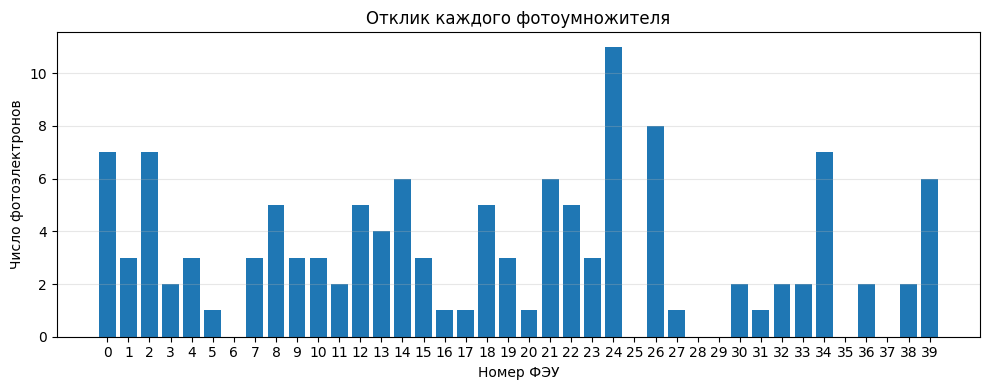

In [6]:
plt.figure(figsize=(10, 4))

plt.bar(np.arange(detector.N), observed_pe)

plt.xlabel("Номер ФЭУ")
plt.ylabel("Число фотоэлектронов")
plt.title("Отклик каждого фотоумножителя")
plt.xticks(np.arange(detector.N))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# Максимальное количество фотонов, учитываемых
# при вычислении суммы вероятностей
K_MAX = 200

def compound_poisson_logp(value, lam, a):

    k = pt.arange(K_MAX + 1)

    # P(K = k), где K ~ Poisson(lam)
    # Обрабатываем случай k = 0 отдельно
    log_p_k = (
        k * pt.log(lam[:, None])
        - lam[:, None]
        - pt.gammaln(k + 1)
    )

    # При lam = 0 выражение 0 * log(0) должно быть равно 0
    log_p_k = pt.switch(
        pt.eq(k, 0),
        -lam[:, None],
        log_p_k
    )

    # P(Q = value | K = k), Q ~ Poisson(a*k)
    mu_pe = a * k

    log_p_q = (
        value[:, None] * pt.log(mu_pe)
        - mu_pe
        - pt.gammaln(value[:, None] + 1)
    )

    # При mu_pe = 0 и value = 0 вероятность равна 1
    log_p_q = pt.switch(
        pt.eq(mu_pe, 0),
        pt.switch(
            pt.eq(value[:, None], 0),
            0.0,
            -np.inf
        ),
        log_p_q
    )

    return pt.logsumexp(log_p_k + log_p_q, axis=1)

In [10]:
# Координаты ФЭУ
pm_positions = pt.as_tensor_variable(
    detector.pm_positions.astype(float)
)

# Наблюдаемые значения
observed_pe = np.asarray(observed_pe, dtype=np.int64)

with pm.Model() as reconstruction_model:

    # Неизвестная энергия события
    E = pm.Uniform(
        "E",
        lower=0.1,
        upper=2.0
    )

    # Неизвестные координаты источника
    x = pm.Uniform(
        "x",
        lower=-0.8,
        upper=0.8
    )

    y = pm.Uniform(
        "y",
        lower=-0.8,
        upper=0.8
    )

    z = pm.Uniform(
        "z",
        lower=-0.8,
        upper=0.8
    )

    # Вектор координат источника
    position = pt.stack([x, y, z])

    # Расстояния от источника до каждого ФЭУ
    delta = pm_positions - position

    distances = pt.sqrt(
        pt.sum(delta**2, axis=1)
    )

    # Косинус угла падения света на фотокатод
    cos_incidence = (
        detector.R**2
        - pt.sum(pm_positions * position, axis=1)
    ) / (detector.R * distances)

    cos_incidence = pt.clip(
        cos_incidence, 0.0, 1.0
    )

    # Вероятность попадания фотона на каждый ФЭУ
    p_hits = (
        detector.r**2
        / (4 * distances**2)
        * cos_incidence
    )

    # Среднее число фотонов, попадающих на каждый ФЭУ
    lambda_hits = source.Y * E * p_hits

    # Правдоподобие наблюдаемого отклика
    pe_observed = pm.CustomDist(
        "pe_observed",
        lambda_hits,
        detector.a,
        logp=compound_poisson_logp,
        observed=observed_pe,
        dtype="int64"
    )

    trace = pm.sample(
        draws=1000,
        tune=1000,
        chains=6,
        cores=3,
        target_accept=0.9,
        random_seed=42
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (6 chains in 3 jobs)
NUTS: [E, x, y, z]


Output()

Sampling 6 chains for 1_000 tune and 1_000 draw iterations (6_000 + 6_000 draws total) took 28 seconds.


In [11]:
summary = az.summary(
    trace,
    var_names=["E", "x", "y", "z"],
    hdi_prob=0.95
)

print(summary)

    mean     sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
E  0.998  0.108     0.792      1.210      0.002    0.002    5238.0    3199.0   
x  0.376  0.181     0.028      0.725      0.003    0.002    4691.0    2464.0   
y -0.059  0.173    -0.393      0.283      0.002    0.002    6392.0    4319.0   
z  0.179  0.185    -0.199      0.527      0.002    0.003    5436.0    3322.0   

   r_hat  
E    1.0  
x    1.0  
y    1.0  
z    1.0  


In [12]:
true_values = {
    "E": E_true,
    "x": position_true[0],
    "y": position_true[1],
    "z": position_true[2]
}

for name, true_value in true_values.items():

    samples = trace.posterior[name].values.flatten()

    mean = np.mean(samples)
    median = np.median(samples)

    low, high = np.quantile(
        samples,
        [0.025, 0.975]
    )

    print(f"\nПараметр {name}:")
    print(f"Истинное значение: {true_value:.3f}")
    print(f"Среднее: {mean:.3f}")
    print(f"Медиана: {median:.3f}")
    print(f"95% интервал: [{low:.3f}, {high:.3f}]")


Параметр E:
Истинное значение: 1.000
Среднее: 0.998
Медиана: 0.993
95% интервал: [0.797, 1.218]

Параметр x:
Истинное значение: 0.300
Среднее: 0.376
Медиана: 0.383
95% интервал: [0.006, 0.710]

Параметр y:
Истинное значение: -0.200
Среднее: -0.059
Медиана: -0.062
95% интервал: [-0.387, 0.293]

Параметр z:
Истинное значение: 0.400
Среднее: 0.179
Медиана: 0.181
95% интервал: [-0.187, 0.544]


Координаты восстановлены менее точно чем энергия

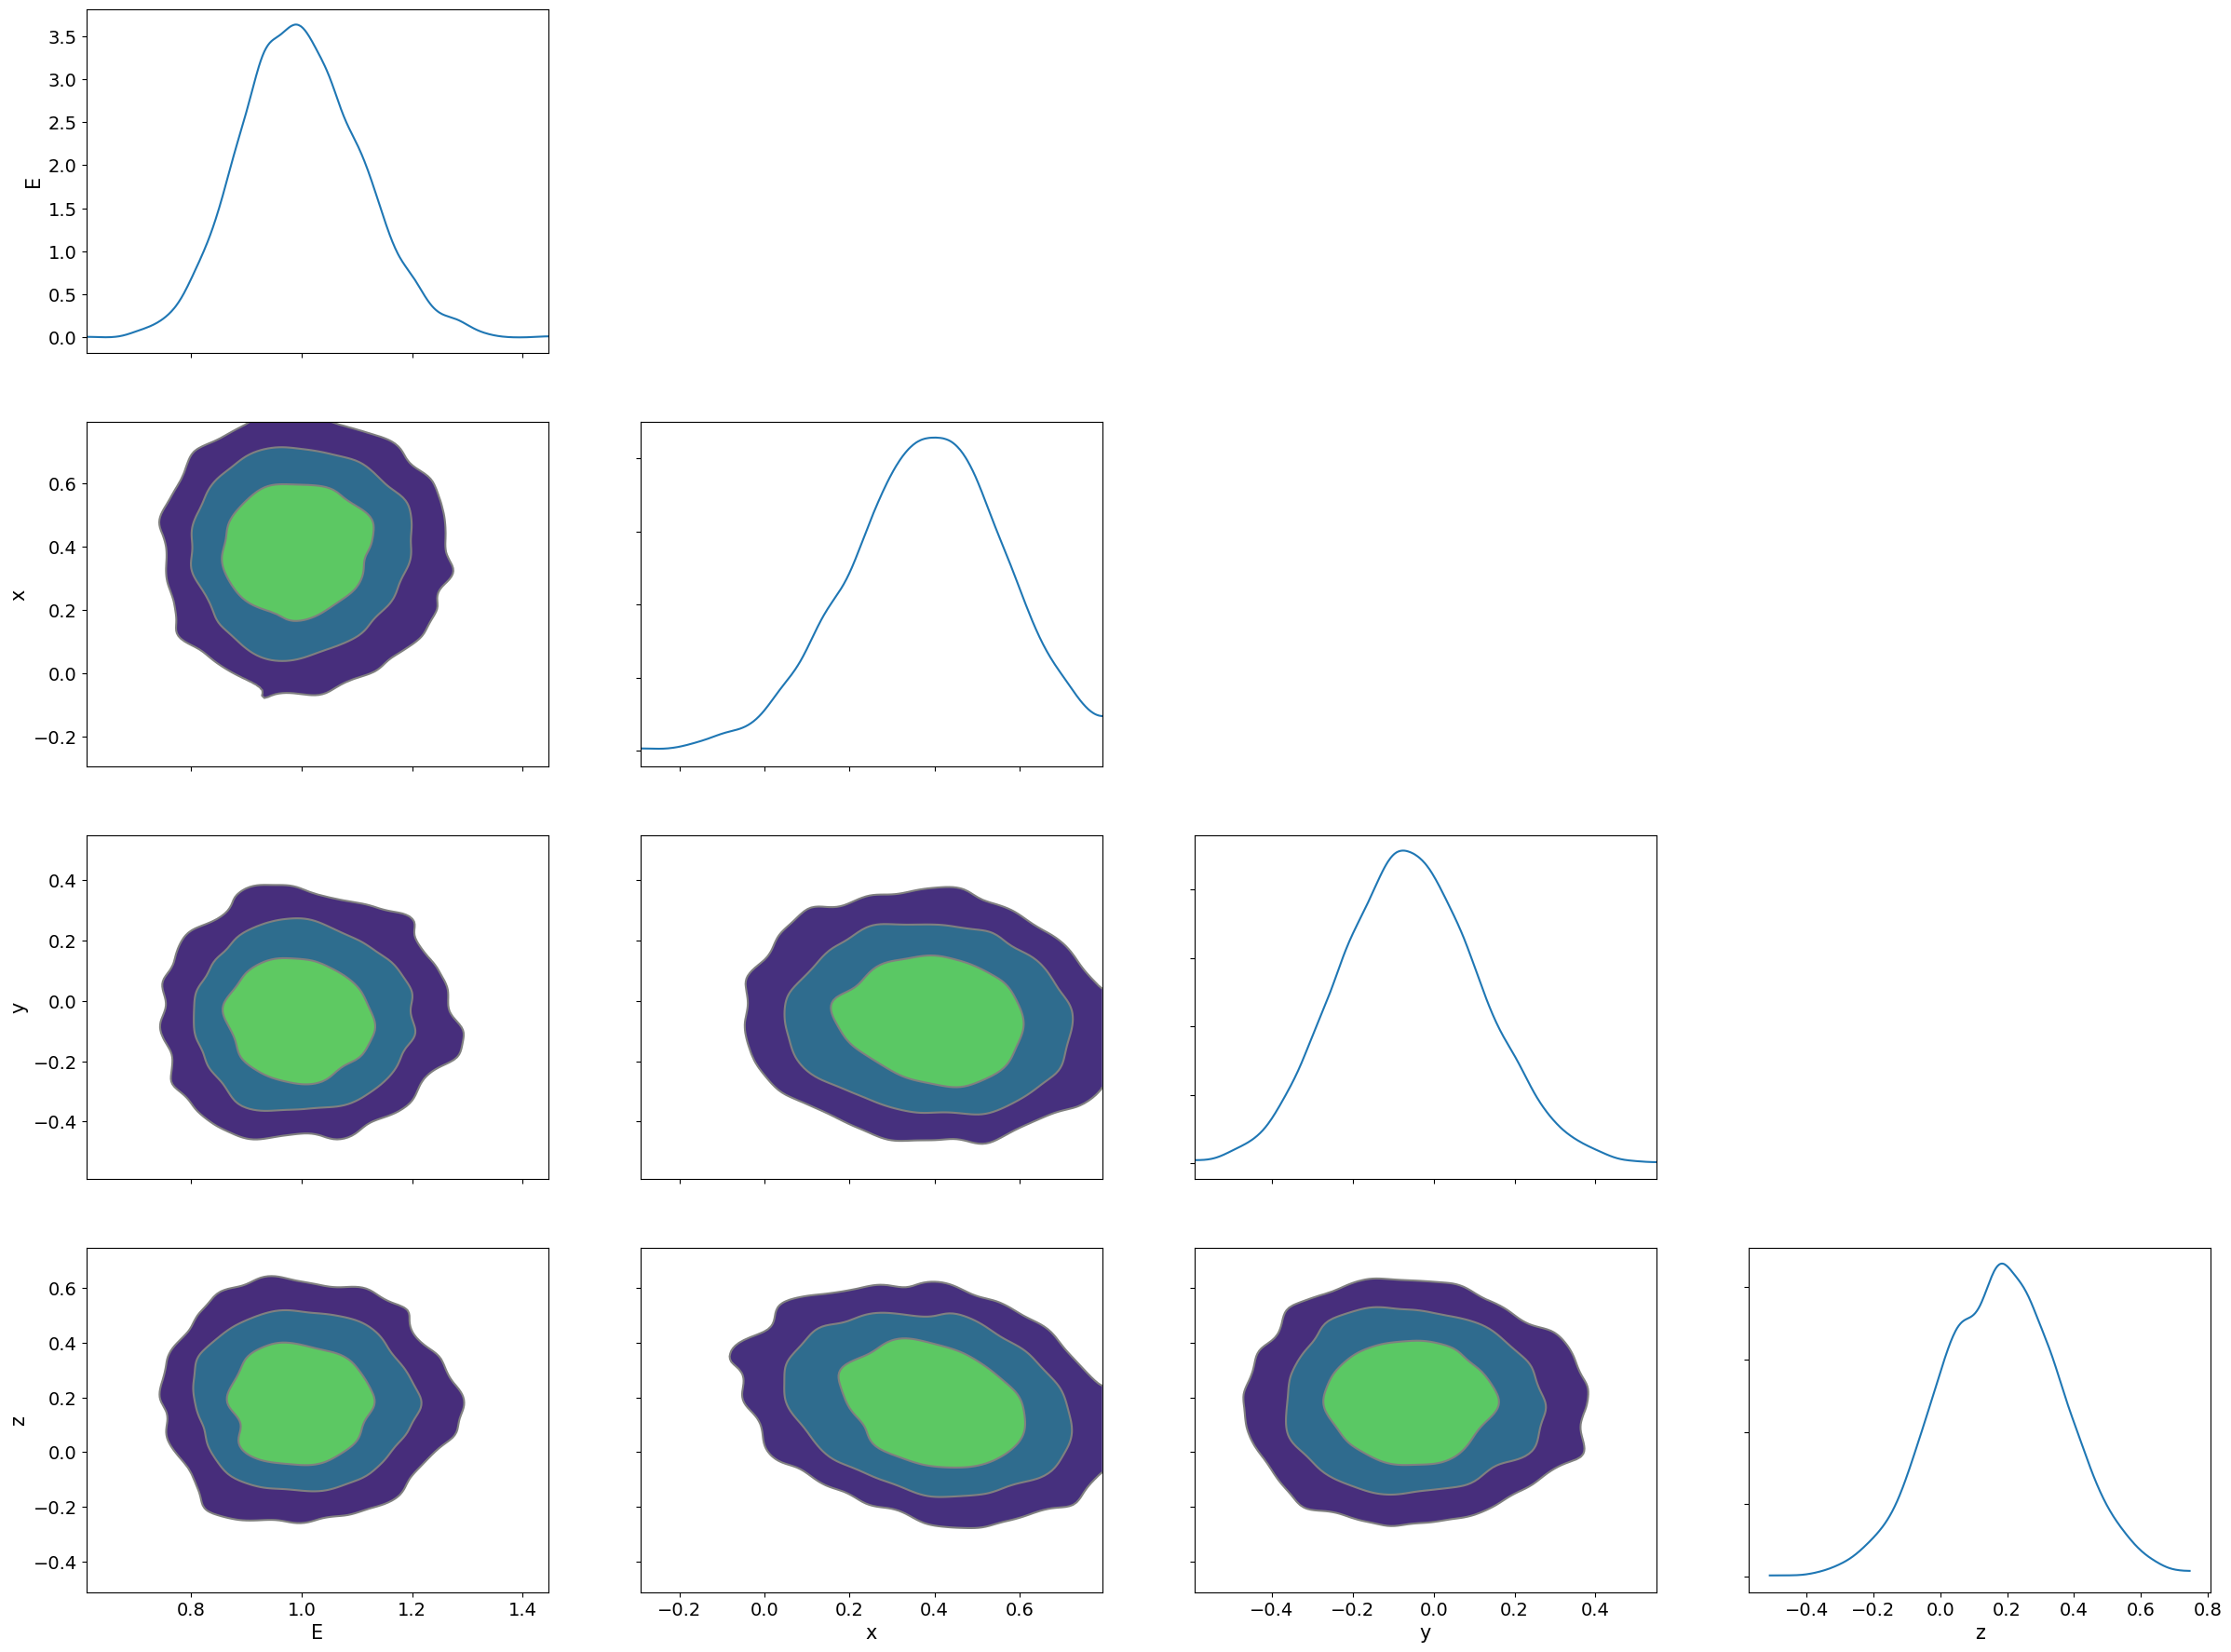

In [13]:
az.plot_pair(
    trace,
    var_names=["E", "x", "y", "z"],
    kind="kde",
    marginals=True
)

plt.show()

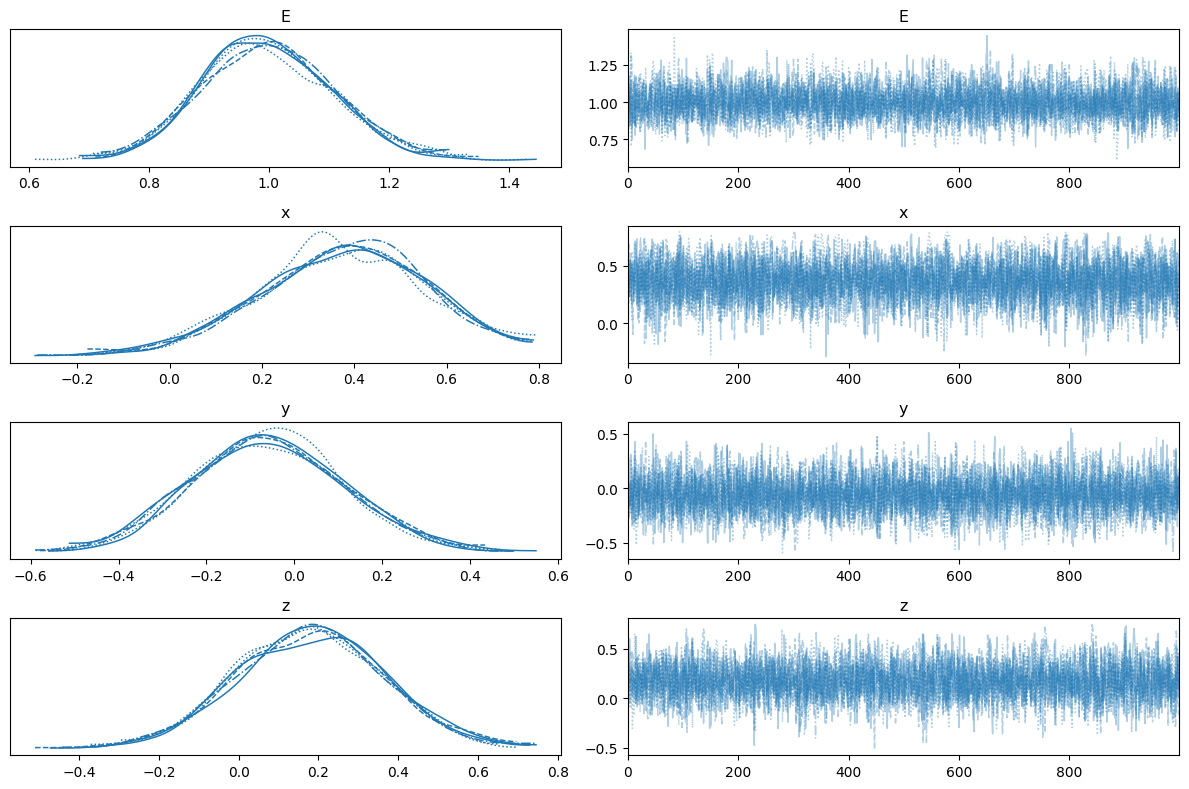

In [18]:
az.plot_trace(
    trace,
    var_names=["E", "x", "y", "z"]
)

plt.tight_layout()
plt.show()